# CSC2042S 2025 Assignment 1: Unsupervised Learning
## Robynne Le Roux 

## 1. Data Preprocessing 

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import random
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

### Load data and reshape

In [2]:
'''pivot and melt'''
df = pd.read_csv('WDICSV.csv')
raw_data = df.values  # Convert to NumPy array
column_names = df.columns.tolist()  # Keep column names as list
#print(f"Loaded {len(df)} rows")
#print(df)

year_columns = [col for col in df.columns 
                if col.isdigit() and len(col) == 4 and 1960 <= int(col) <= 2025] # Identifying year columns

def melt_data(df, year_cols): # Step 1: Melt data (Conver years from coloumns to rows)
    melted_df = pd.melt(df, 
                    id_vars = ['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code'], #specifies which columns to keep as identifier variables 
                    value_vars = year_cols, #which Columns to Melt
                    var_name = 'Year', #What to name the column containing original column names
                    value_name = 'value' #FORGOT NB!!! (go over x rly understand)
                   )     
    melted_df['Year'] = pd.to_numeric(melted_df['Year'])# Convert Year to numeric
    # Skip creating Country_Year here - add it later if needed
    return melted_df
    
def pivot_data(df_long):
    df_wide = df_long.pivot_table(
        index=['Country Name', 'Country Code', 'Year'],
        columns='Indicator Name',
        values='value',  #NB
        aggfunc='first' #no duplicates
    ).reset_index()
    df_wide.columns.name = None # Clean up column names to remove the "Indicator Name" label
    return df_wide

df_long = melt_data(df, year_columns)      
df_wide = pivot_data(df_long)
df_final = df_wide

### testing -to visualise and check data

In [49]:
""" testing -to visualize data """
#print(df)
#print(column_names)
#print(f"shape of data: {melted_df.shape}") #gives rows then cols
#print(f"Columns: {column_names}")
#print(f"First few rows:\n{melted_df[:5]}")
#print(f"Found {len(year_columns)} year columns: {year_columns[:5]}...{year_columns[-5:]}")
#print(melted_df.head(10))
#print(pivoted_df.head())
#print(pivoted_df.columns.tolist())
#print("Final data shape:", pivoted_df.shape)
#print("\nFirst 5 rows, first 8 columns:")
#print(pivoted_df.iloc[:5, :5])
#print(data_matrix)
#print(country_year_labels)
#print(indicator_names)
#print(f"Melted data: {(df_long).head} rows")
#print("Data structure:")
#print(f"Shape: {df_wide.shape}")
#print(f"Index columns: {df_wide.columns[:3].tolist()}")
#print(f"Sample indicator columns: {df_wide.columns[3:8].tolist()}")

#print(f"\nSample rows (country-year pairs):")
#print(df_wide[['Country Name', 'Country Code', 'Year']].head())

#print(f"\nSample data from a few indicators:")
#sample_indicators = df_wide.columns[3:6]  # First 3 indicator columns
#print(df_wide[['Country Name', 'Year'] + list(sample_indicators)].head())
#print(df_final)

' testing -to visualize data '

### Filter data (remove missing data)

In [3]:
'''removes cols where more than x% data missing'''
def remove_cols(df_final, missing=0.5):  # default value 0.5 — change during testing
    filter_cols = df_final.columns[3:]  # Get feature columns (exclude Country Name, Country Code, Year)
    col_missing_perc = df_final[filter_cols].isna().mean()  # Calculate missing prop each feature
    col_keep = col_missing_perc[col_missing_perc <= missing].index  # pandas Index object that provides a way to reference and locate specific rows

    # Create filtered dataset
    id_col = ['Country Name', 'Country Code', 'Year']
    df_filtered = df_final[id_col + list(col_keep)].copy()

    print(f"  Col removal (threshold: {missing}):") 
    print(f"  Original cols: {len(filter_cols)}")
    print(f"  Col kept: {len(col_keep)}")
    print(f"  Col removed: {len(filter_cols) - len(col_keep)}")    
    return df_filtered

'''Remove country-year pairs that don't have data for a sufficient proportion of indicators'''    
def remove_rows(fix_col, missing=0.5):
    available_filter_cols = fix_col.columns[3:]  # Get feature columns again
    row_missing_perc = fix_col[available_filter_cols].notna().mean(axis=1)  # Calculates the mean along axis 1 (across columns for each row): NB REMEMBER THIS NEXT TIME
    rows_keep = row_missing_perc >= missing  # Keep rows with enough available data

    df_filtered = fix_col[rows_keep].copy().reset_index(drop=True)  # drop=True means don't keep the old index as a new column

    print(f"  Row removal (threshold: {missing}):") 
    print(f"  Original rows: {len(fix_col)}")     
    print(f"  Rows kept: {len(df_filtered)}")       
    print(f"  Rows removed: {len(fix_col) - len(df_filtered)}")  
    return df_filtered

#filtered_cols = remove_cols(df_final, missing=0.4)
#filtered_rows = remove_rows(filtered_cols, missing=0.6)

### Filter data testing (optimal threshold combo -coverage and completeness)

In [4]:
'''use lower threshold for columns since they are harder to replace'''
def test_threshold_combinations(df, col_perc_wanted=[0.2, 0.3, 0.4, 0.5], 
                                row_perc_wanted=[0.5, 0.6, 0.7, 0.8, 0.9]):
    print(f"\nInitial shape: {df.shape}")
    results = []

    for col_thresh in col_perc_wanted:
        for row_thresh in row_perc_wanted:
            print(f"\nTesting thresholds - Columns: {col_thresh}, Rows: {row_thresh}")

            # Step 1: Remove columns with too much missing data
            df_cols_filtered = remove_cols(df, col_thresh)

            # Step 2: Remove rows with insufficient data
            df_filtered = remove_rows(df_cols_filtered, row_thresh)

            # Identify feature columns (exclude ID columns)
            id_cols = ['Country Name', 'Country Code', 'Year']
            features = [col for col in df_filtered.columns if col not in id_cols]

            # Calculate missing rate and retention
            total_cells = len(df_filtered) * len(features)
            missing_cells = df_filtered[features].isna().sum().sum()
            retention = (total_cells - missing_cells) / ((len(df) * (len(df.columns) - 3)))

            results.append({
                'col_threshold': col_thresh,
                'row_threshold': row_thresh,
                'rows': len(df_filtered),
                'features': len(features),
                'retention_rate': round(retention, 4)
            })

            print(f"Rows kept: {len(df_filtered)}")
            print(f"Features kept: {len(features)}")
            print(f"Retention: {round(retention * 100, 1)}%")

    # Compile results
    results_df = pd.DataFrame(results)
    print("\nTop 5 setups with the most data kept:")
    top5 = results_df.sort_values(by='retention_rate', ascending=False).head(5)
    print(top5[['col_threshold', 'row_threshold', 'rows', 'features', 'retention_rate']].to_string(index=False))

    return results_df
    
# Run the function and store the results
results_df = test_threshold_combinations(df_final)

print("\nAll combinations tested:")
print(results_df[['col_threshold', 'row_threshold', 'rows', 'features', 'retention_rate']])


Initial shape: (17225, 1518)

Testing thresholds - Columns: 0.2, Rows: 0.5
  Col removal (threshold: 0.2):
  Original cols: 1515
  Col kept: 103
  Col removed: 1412
  Row removal (threshold: 0.5):
  Original rows: 17225
  Rows kept: 17225
  Rows removed: 0
Rows kept: 17225
Features kept: 103
Retention: 6.6%

Testing thresholds - Columns: 0.2, Rows: 0.6
  Col removal (threshold: 0.2):
  Original cols: 1515
  Col kept: 103
  Col removed: 1412
  Row removal (threshold: 0.6):
  Original rows: 17225
  Rows kept: 17195
  Rows removed: 30
Rows kept: 17195
Features kept: 103
Retention: 6.5%

Testing thresholds - Columns: 0.2, Rows: 0.7
  Col removal (threshold: 0.2):
  Original cols: 1515
  Col kept: 103
  Col removed: 1412
  Row removal (threshold: 0.7):
  Original rows: 17225
  Rows kept: 17162
  Rows removed: 63
Rows kept: 17162
Features kept: 103
Retention: 6.5%

Testing thresholds - Columns: 0.2, Rows: 0.8
  Col removal (threshold: 0.2):
  Original cols: 1515
  Col kept: 103
  Col remove

### Implement 0.5, 0.5 data filter

In [5]:
# Get the cleaned dataset with optimal thresholds (0.5, 0.5)
df_cleaned = remove_cols(df_final, 0.5)
df_cleaned = remove_rows(df_cleaned, 0.5)
#print(df_cleaned)

  Col removal (threshold: 0.5):
  Original cols: 1515
  Col kept: 380
  Col removed: 1135
  Row removal (threshold: 0.5):
  Original rows: 17225
  Rows kept: 13176
  Rows removed: 4049


### Data imputation (fill empty cells and normalisation)

In [6]:
"""Find missing positions and fill each with median"""
def missing_pos_fill(df):    
    id_cols = ['Country Name', 'Country Code', 'Year']
    indicator_cols = [col for col in df.columns if col not in id_cols]
    df_imputed = df.copy()
    df_imputed[indicator_cols] = df[indicator_cols].fillna(df[indicator_cols].median())
    return df_imputed
    
def normalise(df):
    id_cols = ['Country Name', 'Country Code', 'Year']
    indicator_cols = [col for col in df.columns if col not in id_cols]
    df_normalized = df.copy()
    df_normalized[indicator_cols] = (df[indicator_cols] - df[indicator_cols].min()) / (
                                     df[indicator_cols].max() - df[indicator_cols].min())
    return df_normalized

df_imputed = missing_pos_fill(df_cleaned)
df_normalized = normalise(df_imputed)
#print(df_normalized)

### Visualisation  t-SNE

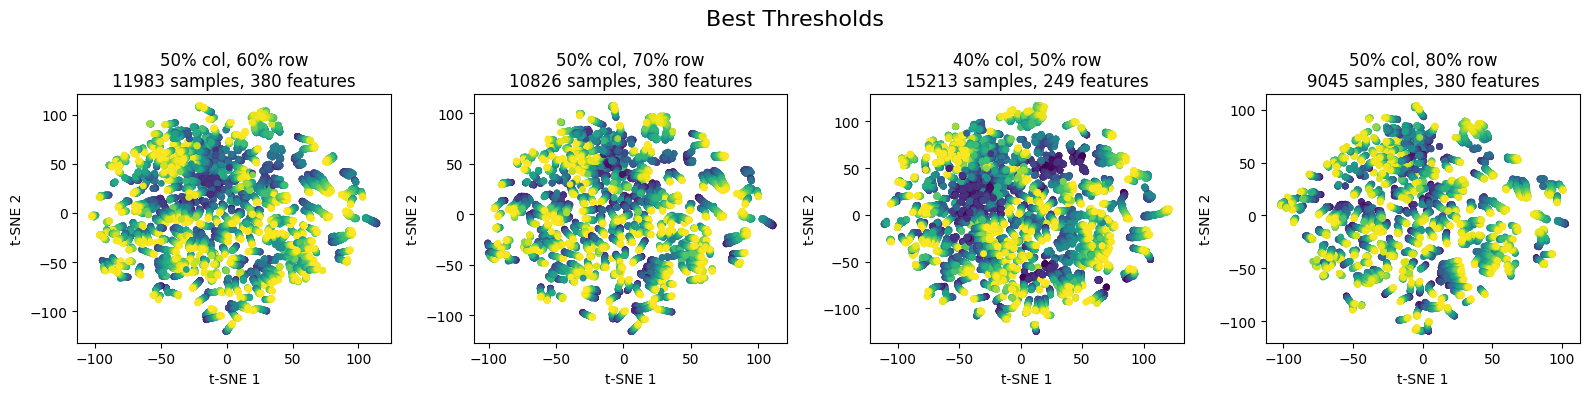

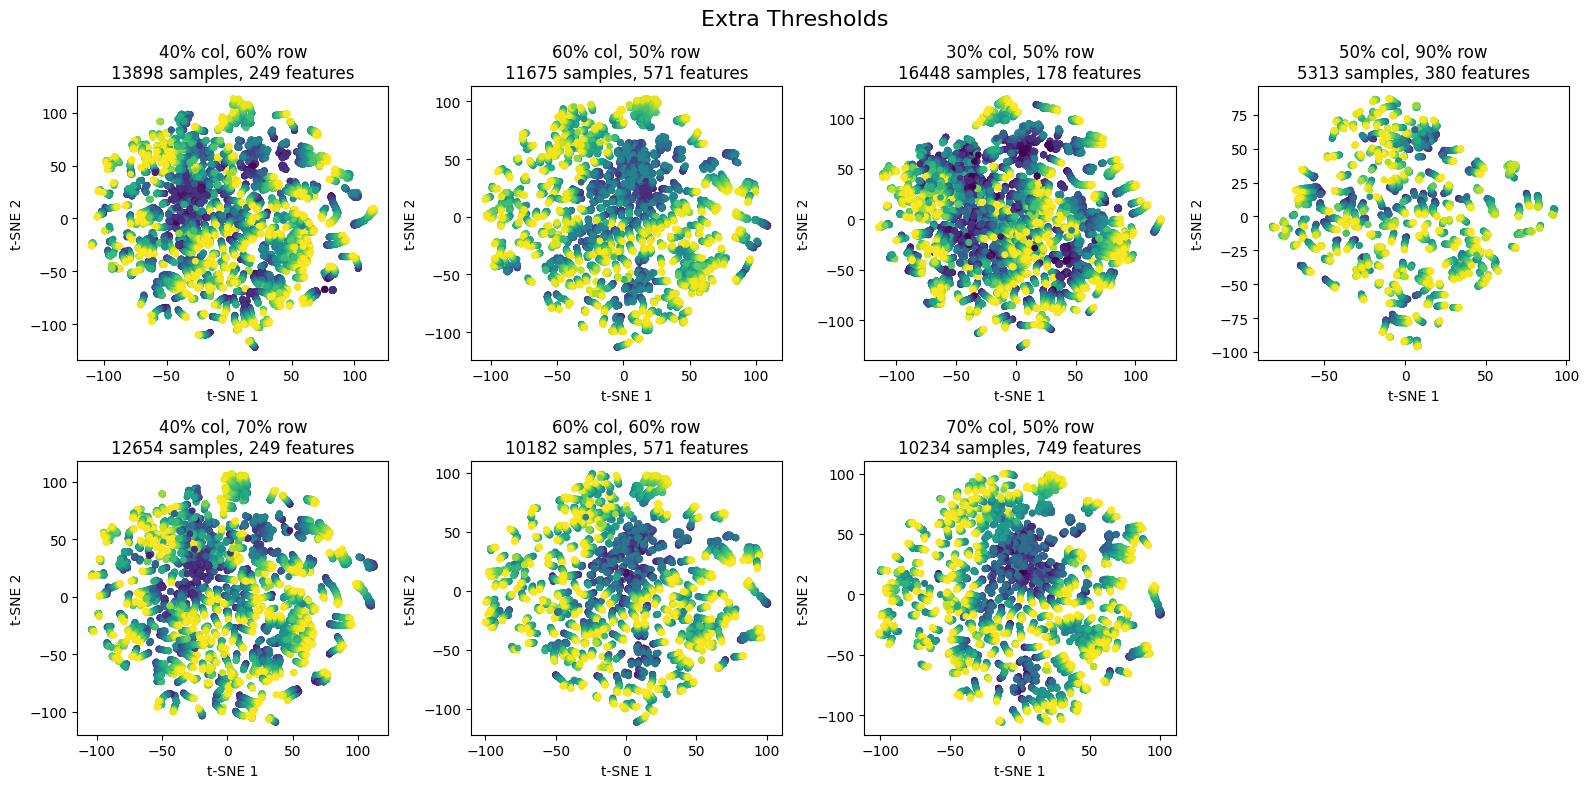


Showing data at each stage of preprocessing...
Original shape: (17225, 1518)
After threshold filtering: (13176, 383)
Number of features kept: 380
Missing values filled and features normalized.


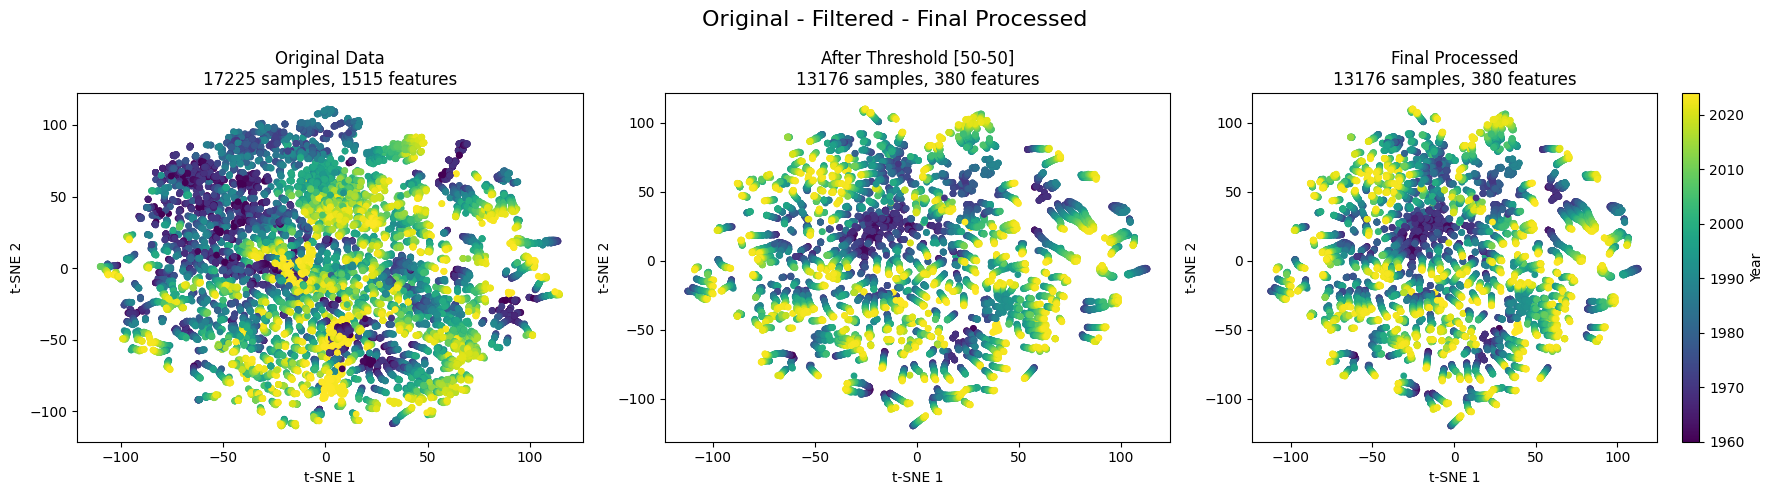

In [166]:
def process_threshold(df, col_thresh, row_thresh):
    id_cols = ['Country Name', 'Country Code', 'Year']
    indicator_cols = [col for col in df.columns if col not in id_cols]

    missing_per_feature = df[indicator_cols].isna().mean()
    good_features = missing_per_feature[missing_per_feature <= col_thresh].index

    df_temp = df[id_cols + list(good_features)].copy()
    data_per_row = df_temp[good_features].notna().mean(axis=1)  # percentaege of available data per row
    good_rows = data_per_row >= row_thresh

    df_clean = df_temp[good_rows].copy()
    return df_clean, good_features


def plot_tsne(df, features, title, ax):
    X = df[features].values

    if np.isnan(X).any():
        X = SimpleImputer(strategy='mean').fit_transform(X)

    X = StandardScaler().fit_transform(X)

    perp = min(30, max(5, X.shape[0] // 4))
    tsne_result = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X)

    scatter = ax.scatter(tsne_result[:, 0], tsne_result[:, 1], c=df['Year'], s=15, cmap='viridis')
    ax.set_title(f'{title}\n{X.shape[0]} samples, {X.shape[1]} features')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')

    return scatter  # return the mapable object

def visualize_all_thresholds(df):
    best_thresholds = [
        (0.5, 0.6, "50% col, 60% row"),
        (0.5, 0.7, "50% col, 70% row"),
        (0.4, 0.5, "40% col, 50% row"),
        (0.5, 0.8, "50% col, 80% row")
    ]
    additional_thresholds = [
        (0.4, 0.6, "40% col, 60% row"),
        (0.6, 0.5, "60% col, 50% row"),
        (0.3, 0.5, "30% col, 50% row"),
        (0.5, 0.9, "50% col, 90% row"),
        (0.4, 0.7, "40% col, 70% row"),
        (0.6, 0.6, "60% col, 60% row"),
        (0.7, 0.5, "70% col, 50% row")
    ]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    fig.suptitle('Best Thresholds', fontsize=16)

    for i, (col, row, label) in enumerate(best_thresholds):
        df_clean, features = process_threshold(df, col, row)
        plot_tsne(df_clean, features, label, axes[i])

    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()
    fig.suptitle('Extra Thresholds', fontsize=16)

    for i, (col, row, label) in enumerate(additional_thresholds):
        df_clean, features = process_threshold(df, col, row)
        plot_tsne(df_clean, features, label, axes[i])

    axes[7].set_visible(False)  # hide unused subplot
    plt.tight_layout()
    plt.show()
    
def show_data_processing_stages(df):
    id_cols = ['Country Name', 'Country Code', 'Year']
    all_features = [col for col in df.columns if col not in id_cols]

    print("\nShowing data at each stage of preprocessing...")

    df_clean, selected_features = process_threshold(df, 0.5, 0.5)

    print(f"Original shape: {df.shape}")
    print(f"After threshold filtering: {df_clean.shape}")
    print(f"Number of features kept: {len(selected_features)}")

    df_imputed = df_clean.copy()
    df_imputed[selected_features] = SimpleImputer(strategy='mean').fit_transform(df_clean[selected_features])

    df_normalized = df_imputed.copy()
    df_normalized[selected_features] = StandardScaler().fit_transform(df_imputed[selected_features])

    print("Missing values filled and features normalized.")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Original - Filtered - Final Processed', fontsize=16)

    plot_tsne(df, all_features, "Original Data", axes[0])
    plot_tsne(df_clean, selected_features, "After Threshold [50-50]", axes[1])
    scatter = plot_tsne(df_normalized, selected_features, "Final Processed", axes[2])

    plt.colorbar(scatter, ax=axes[2], label='Year')
    plt.tight_layout()
    plt.show()

    return df_normalized, selected_features
    
visualize_all_thresholds(df_final) # Show t-SNE plots for different threshold combinations

df_processed, feature_cols = show_data_processing_stages(df_final) # Show the 3 main preprocessing stages

## 2. K-means Clustering and Initialization

### Implement (common methods)

In [7]:
'''NB: code adapted from K-means clustering LAB'''
def compute_cluster_mean(cluster_data):
    return np.mean(cluster_data, axis=0)
    
def compute_euclidean_distance(x1, x2):
    return np.linalg.norm(x1 - x2)
    
def form_new_clusters(X, centroids): # Assignment Step
    clusters = [ [] for _ in centroids]
    for x in X:
        centroid_distances = [compute_euclidean_distance(x, c) for c in centroids]
        new_cluster = np.argmin(centroid_distances)
        clusters[new_cluster].append(x)
    
    return clusters
def compute_new_centroids(cluster_list): # Update Step
    centroids = []
    for cluster_data in cluster_list:
        new_centroid = compute_cluster_mean(cluster_data)
        centroids.append(new_centroid)
    return centroids

### Random initialization implementation

In [8]:
# running the algorithm multiple times with different random seeds to assess the variability in results.
def initialise_centroids_random(X, k, random_seed=None):        
    if random_seed is not None:  #The random_seed=None default parameter means randomness is preserved unless you explicitly want reproducibility.
        random.seed(random_seed)
    indices = random.sample(range(len(X)), k)
    return [X[i].copy() for i in indices]

###  K-means++ initialization implementation

In [9]:
# uses weighted random sampling where the probability of selection is proportional to squared distance

def initialise_centroids_kmeans_plus_plus(X, k, random_seed=None):
    """k-means++ initialization - selects centroids that are far apart"""
            
    if random_seed is not None:
        np.random.seed(random_seed)  # set seed for 
    
    centroids = []
    
    first_idx = np.random.randint(len(X))  # pick first centroid randomly
    centroids.append(X[first_idx].copy())
    
    # pick remaining centroids
    for _ in range(k - 1):
        distances = []
        for point in X:
            # find distance to nearest existing centroid
            min_dist = min([compute_euclidean_distance(point, centroid) for centroid in centroids])
            distances.append(min_dist ** 2)  # square the distance
        
        distances = np.array(distances)
        probabilities = distances / distances.sum()  # turn distances into probabilities
        cumulative_prob = np.cumsum(probabilities)  # cumulative distribution
        
        r = np.random.rand()  # random number between 0 and 1
        next_idx = np.searchsorted(cumulative_prob, r)  # find index where r fits in distribution
        next_idx = min(next_idx, len(X) - 1)  # avoid going out of bounds
        centroids.append(X[next_idx].copy())
    
    return centroids

### Analysis (nr iterations -> convergence, loss func, stability cluster)


Running K-means with k=5 over 10 runs...

Random Init:
  Avg WCSS: 30439.68
  Avg Iterations: 44.8

K-means++ Init:
  Avg WCSS: 30441.53
  Avg Iterations: 35.6


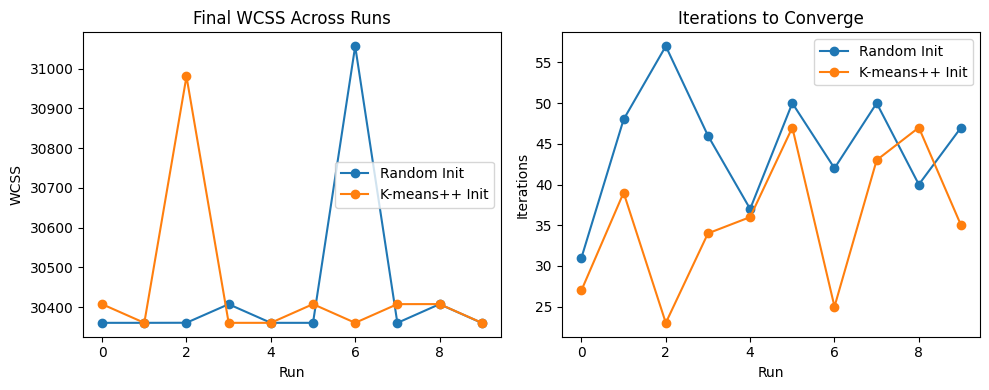

Data verification:
Shape: (13176, 380)
Mean: 0.1676
Std: 0.2399
Min: 0.0000
Max: 1.0000


In [10]:
def calculate_wcss(clusters, centroids):
    """Calculate Within-Cluster Sum of Squares (loss function)"""
    wcss = 0
    for i, cluster in enumerate(clusters):
        for point in cluster:
            wcss += np.linalg.norm(point - centroids[i]) ** 2 # Compute loss function (WCSS)
    return wcss
    
def repeat_until_convergence(X, clusters, centroids, max_iters=100):
    for i in range(max_iters):
        new_centroids = compute_new_centroids(clusters)
        new_clusters = form_new_clusters(X, new_centroids)
        
        if has_converged(centroids, new_centroids): # Track number of iterations until convergence
            return new_clusters, new_centroids, i + 1

        centroids = new_centroids
        clusters = new_clusters

    return clusters, centroids, max_iters
    
def run_kmeans_multiple_times(X, k, init_func, runs=10):
    all_wcss = []
    all_iters = []
    all_labels = []

    for seed in range(runs):
        centroids = init_func(X, k, random_seed=seed)
        initial_clusters = form_new_clusters(X, centroids)
        final_clusters, final_centroids, iterations = repeat_until_convergence(X, initial_clusters, centroids)

        wcss = calculate_wcss(final_clusters, final_centroids) # store final loss value for specifc run

        all_wcss.append(wcss) # store nr iterations to convergence
        all_iters.append(iterations)

        labels = np.zeros(len(X), dtype=int) # store cluster labels assess stability across runs
        for i, cluster in enumerate(final_clusters):
            for point in cluster:
                idx = np.where((X == point).all(axis=1))[0][0]
                labels[idx] = i
        all_labels.append(labels)

    return all_wcss, all_iters, all_labels
    
def plot_convergence_metrics(wcss_rand, iters_rand, wcss_pp, iters_pp):
    """Plot WCSS and iteration count for both init strategies"""
    import matplotlib.pyplot as plt

    plt.figure(figsize=(10, 4))

    # WCSS comparison
    plt.subplot(1, 2, 1)
    plt.plot(wcss_rand, label='Random Init', marker='o')
    plt.plot(wcss_pp, label='K-means++ Init', marker='o')
    plt.title('Final WCSS Across Runs')
    plt.xlabel('Run')
    plt.ylabel('WCSS')
    plt.legend()

    # Iteration comparison
    plt.subplot(1, 2, 2)
    plt.plot(iters_rand, label='Random Init', marker='o')
    plt.plot(iters_pp, label='K-means++ Init', marker='o')
    plt.title('Iterations to Converge')
    plt.xlabel('Run')
    plt.ylabel('Iterations')
    plt.legend()

    plt.tight_layout()
    plt.show()
    
def has_converged(old_centroids, new_centroids, tolerance=1e-4):
    for old, new in zip(old_centroids, new_centroids):
        if compute_euclidean_distance(old, new) > tolerance:
            return False
    return True
    
def compare_initialization_strategies(X, k=5, runs=10):
    """Run both init strategies and compare results"""
    print(f"\nRunning K-means with k={k} over {runs} runs...")

    wcss_rand, iters_rand, _ = run_kmeans_multiple_times(X, k, initialise_centroids_random, runs)
    wcss_pp, iters_pp, _ = run_kmeans_multiple_times(X, k, initialise_centroids_kmeans_plus_plus, runs)

    print("\nRandom Init:")
    print(f"  Avg WCSS: {np.mean(wcss_rand):.2f}")
    print(f"  Avg Iterations: {np.mean(iters_rand):.1f}")

    print("\nK-means++ Init:")
    print(f"  Avg WCSS: {np.mean(wcss_pp):.2f}")
    print(f"  Avg Iterations: {np.mean(iters_pp):.1f}")

    plot_convergence_metrics(wcss_rand, iters_rand, wcss_pp, iters_pp)
    
# Extract only numeric features for clustering
id_cols = ['Country Name', 'Country Code', 'Year']
feature_cols = [col for col in df_normalized.columns if col not in id_cols]
X = df_normalized[feature_cols].values
compare_initialization_strategies(X, k=5, runs=10)

def calculate_cluster_stability(all_labels):
    """Calculate how consistent cluster assignments are across runs"""
    from sklearn.metrics import adjusted_rand_score
    
    stability_scores = []
    for i in range(len(all_labels)):
        for j in range(i+1, len(all_labels)):
            ari = adjusted_rand_score(all_labels[i], all_labels[j])
            stability_scores.append(ari)
    
    return np.mean(stability_scores)
def analyze_initialization_performance(wcss_rand, iters_rand, wcss_pp, iters_pp):
    """Provide data-driven analysis of initialization strategies"""
    
    print("\nINITIALIZATION STRATEGY ANALYSIS")
    print("="*50)
    
    # Convergence speed
    avg_iters_rand = np.mean(iters_rand)
    avg_iters_pp = np.mean(iters_pp)
    speed_improvement = (avg_iters_rand - avg_iters_pp) / avg_iters_rand * 100
    
    # Solution quality
    avg_wcss_rand = np.mean(wcss_rand)
    avg_wcss_pp = np.mean(wcss_pp)
    quality_improvement = (avg_wcss_rand - avg_wcss_pp) / avg_wcss_rand * 100
    
    # Variability
    var_wcss_rand = np.std(wcss_rand)
    var_wcss_pp = np.std(wcss_pp)
    consistency_improvement = (var_wcss_rand - var_wcss_pp) / var_wcss_rand * 100
    
    print(f"Convergence Speed:")
    print(f"  Random: {avg_iters_rand:.1f} iterations")
    print(f"  K-means++: {avg_iters_pp:.1f} iterations")
    print(f"  Improvement: {speed_improvement:.1f}%")
    
    print(f"\nSolution Quality:")
    print(f"  Random WCSS: {avg_wcss_rand:.1f}")
    print(f"  K-means++ WCSS: {avg_wcss_pp:.1f}")
    print(f"  Improvement: {quality_improvement:.1f}%")
    
    print(f"\nConsistency:")
    print(f"  Random std: {var_wcss_rand:.1f}")
    print(f"  K-means++ std: {var_wcss_pp:.1f}")
    print(f"  Improvement: {consistency_improvement:.1f}%")
    
    print(f"\nRECOMMENDATION:")
    if quality_improvement > 5 and speed_improvement > 10:
        print("K-means++ is strongly recommended due to superior quality and speed.")
    elif quality_improvement > 0 and speed_improvement > 0:
        print("K-means++ is recommended due to consistent improvements.")
    else:
        print("Both methods perform similarly on this dataset.")

X = df_normalized[feature_cols].values
print("Data verification:")
print(f"Shape: {X.shape}")
print(f"Mean: {X.mean():.4f}")
print(f"Std: {X.std():.4f}")
print(f"Min: {X.min():.4f}")
print(f"Max: {X.max():.4f}")

## 3. Convergence Criteria 

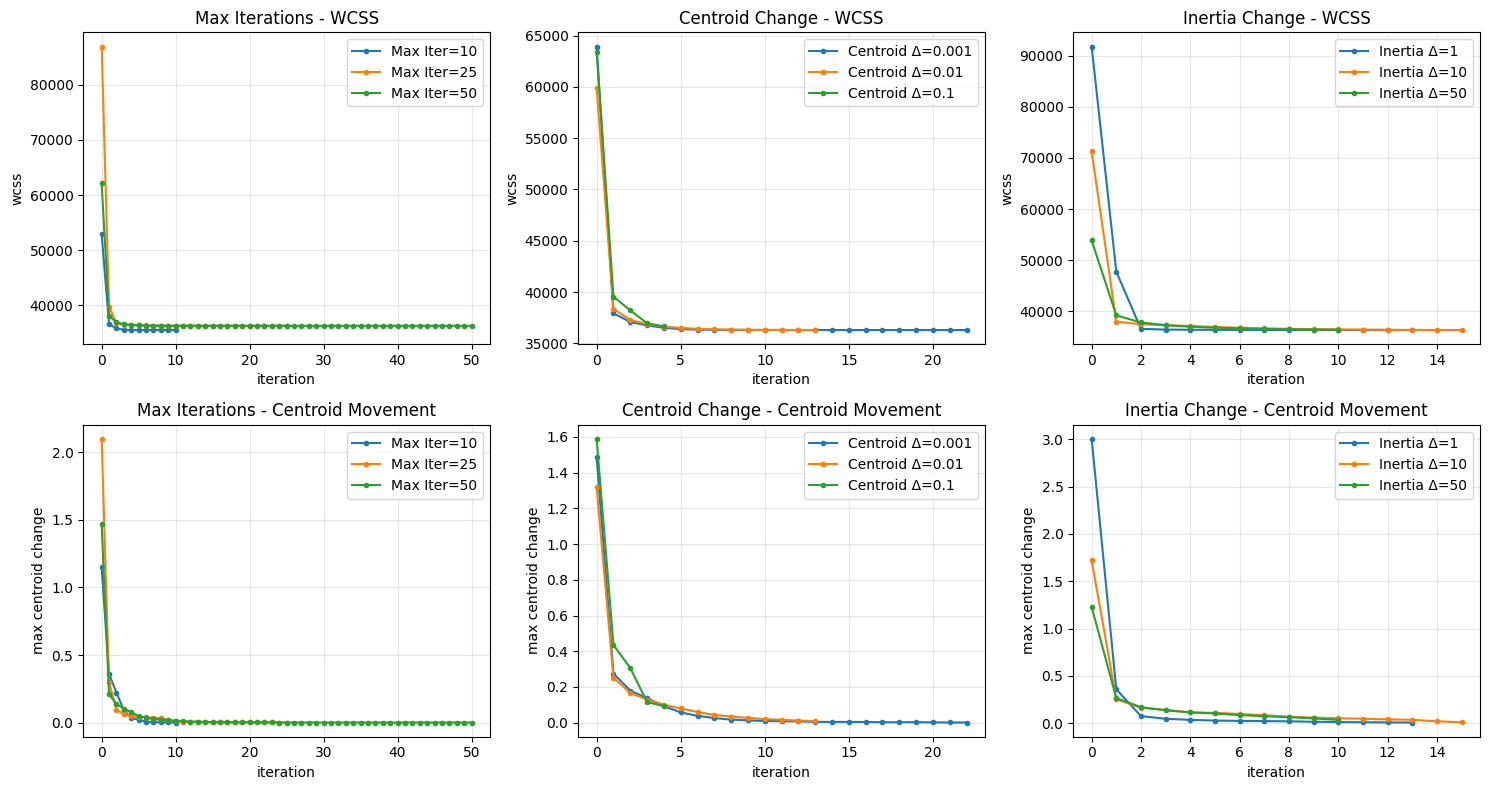

CONVERGENCE CRITERIA ANALYSIS

MAX ITERATIONS:
  Max Iter=10     | Iter: 10 | WCSS: 35542.1 | Efficiency: High
  Max Iter=25     | Iter: 25 | WCSS: 36305.9 | Efficiency: Medium
  Max Iter=50     | Iter: 50 | WCSS: 36305.8 | Efficiency: Low
  Centroid Δ=0.001 | Iter: 22 | WCSS: 36305.8 | Efficiency: Medium
  Centroid Δ=0.01 | Iter: 13 | WCSS: 36309.1 | Efficiency: High
  Centroid Δ=0.1  | Iter:  4 | WCSS: 36654.1 | Efficiency: High
  Inertia Δ=1     | Iter: 13 | WCSS: 36307.7 | Efficiency: High
  Inertia Δ=10    | Iter: 15 | WCSS: 36308.8 | Efficiency: Medium
  Inertia Δ=50    | Iter: 10 | WCSS: 36365.7 | Efficiency: High

CENTROID CHANGE:
  Max Iter=10     | Iter: 10 | WCSS: 35542.1 | Efficiency: High
  Max Iter=25     | Iter: 25 | WCSS: 36305.9 | Efficiency: Medium
  Max Iter=50     | Iter: 50 | WCSS: 36305.8 | Efficiency: Low
  Centroid Δ=0.001 | Iter: 22 | WCSS: 36305.8 | Efficiency: Medium
  Centroid Δ=0.01 | Iter: 13 | WCSS: 36309.1 | Efficiency: High
  Centroid Δ=0.1  | Iter:  4 

In [11]:
def kmeans_with_convergence_tracking(X, k, criterion_type, threshold, max_iter=100):
    centroids = initialise_centroids_random(X, k)
    clusters = form_new_clusters(X, centroids)

    wcss_history = []
    centroid_changes = []
    iterations = 0

    while iterations < max_iter:
        current_wcss = calculate_wcss(clusters, centroids)
        wcss_history.append(current_wcss)

        new_clusters = form_new_clusters(X, centroids)
        new_centroids = compute_new_centroids(new_clusters)

        # get max movement across centroids
        centroid_change = max([compute_euclidean_distance(centroids[i], new_centroids[i]) 
                               for i in range(len(centroids))])
        centroid_changes.append(centroid_change)

        # check stopping condition based on selected criterion
        if criterion_type == 'max_iterations' and iterations >= threshold:
            break
        elif criterion_type == 'centroid_change' and centroid_change < threshold:
            break
        elif criterion_type == 'inertia_change' and iterations > 0:
            inertia_change = abs(wcss_history[-2] - wcss_history[-1])  # change in loss
            if inertia_change < threshold:
                break

        centroids = new_centroids
        clusters = new_clusters
        iterations += 1

    return clusters, centroids, wcss_history, centroid_changes, iterations


def run_convergence_analysis(X, k=3):
    convergence_configs = {
        'max_iter_10': {'type': 'max_iterations', 'threshold': 10, 'name': 'Max Iter=10'},
        'max_iter_25': {'type': 'max_iterations', 'threshold': 25, 'name': 'Max Iter=25'},
        'max_iter_50': {'type': 'max_iterations', 'threshold': 50, 'name': 'Max Iter=50'},
        'centroid_0.001': {'type': 'centroid_change', 'threshold': 0.001, 'name': 'Centroid Δ=0.001'},
        'centroid_0.01':  {'type': 'centroid_change', 'threshold': 0.01,  'name': 'Centroid Δ=0.01'},
        'centroid_0.1':   {'type': 'centroid_change', 'threshold': 0.1,   'name': 'Centroid Δ=0.1'},
        'inertia_1':  {'type': 'inertia_change', 'threshold': 1.0,  'name': 'Inertia =1'},
        'inertia_10': {'type': 'inertia_change', 'threshold': 10.0, 'name': 'Inertia =10'},
        'inertia_50': {'type': 'inertia_change', 'threshold': 50.0, 'name': 'Inertia =50'}
    }
    results = {}
    for config_name, config in convergence_configs.items():
        clusters, centroids, wcss_hist, centroid_hist, final_iter = kmeans_with_convergence_tracking(
            X, k=k,
            criterion_type=config['type'],
            threshold=config['threshold'],
            max_iter=100
        )
        results[config_name] = {
            'config': config,
            'iterations': final_iter,
            'final_wcss': wcss_hist[-1],
            'wcss_history': wcss_hist,
            'centroid_changes': centroid_hist
        }
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    criterion_types = ['max_iterations', 'centroid_change', 'inertia_change']

    for i, ctype in enumerate(criterion_types):
        for config_name, result in results.items():
            if result['config']['type'] == ctype:
                axes[i].plot(result['wcss_history'], 'o-', label=result['config']['name'], markersize=3)
                axes[i+3].plot(result['centroid_changes'], 'o-', label=result['config']['name'], markersize=3)

        axes[i].set_title(f'{ctype.replace("_", " ").title()} - WCSS')
        axes[i+3].set_title(f'{ctype.replace("_", " ").title()} - Centroid Movement')
        axes[i].set_xlabel('iteration')
        axes[i+3].set_xlabel('iteration')
        axes[i].set_ylabel('wcss')
        axes[i+3].set_ylabel('max centroid change')
        axes[i].legend()
        axes[i+3].legend()
        axes[i].grid(True, alpha=0.3)
        axes[i+3].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("CONVERGENCE CRITERIA ANALYSIS")
    print("="*60)

    for ctype in criterion_types:
        print(f"\n{ctype.replace('_', ' ').upper()}:")
        for config_name, result in results.items():
            efficiency = 'High' if result['iterations'] < 15 else 'Medium' if result['iterations'] < 30 else 'Low'
            print(f"  {result['config']['name']:15} | Iter: {result['iterations']:2d} | WCSS: {result['final_wcss']:6.1f} | Efficiency: {efficiency}")

    return results

X = df_normalized[feature_cols].values
results = run_convergence_analysis(X, k=3)

## 4. Determining the Optimal K

### Visualisation

In [ ]:
def run_kmeans_multiple_k(X, k_range=range(2, 16)):
    results = {}
    for k in k_range:
        try:
            res = kmeans_with_convergence_tracking(X, k, criterion="max_iterations", threshold=100)
            inertia = res[2][-1] if isinstance(res[2], (list, np.ndarray)) else res[2]
            results[k] = {
                "inertia": float(inertia),
                "labels": res[0],
                "centroids": res[1]
            }
        except Exception as e:
            print(f"error at k={k}: {e}")
    return results
    
def detect_elbow_k(inertias, ks):
    # fit line between first and last points
    p1 = np.array([ks[0], inertias[0]])
    p2 = np.array([ks[-1], inertias[-1]])

    # compute distance of each point to line
    distances = []
    for i in range(len(ks)):
        p = np.array([ks[i], inertias[i]])
        d = np.linalg.norm(np.cross(p2 - p1, p1 - p)) / np.linalg.norm(p2 - p1)
        distances.append(d)

    elbow_index = np.argmax(distances)
    return ks[elbow_index]

def plot_elbow_and_detect(results):
    ks = sorted(results.keys())
    inertias = [results[k]["inertia"] for k in ks]

    plt.figure(figsize=(8, 5))
    plt.plot(ks, inertias, marker='o', color='navy')
    plt.xlabel("number of clusters (k)")
    plt.ylabel("loss (SSE)")
    plt.title("elbow method")
    plt.grid(True, alpha=0.3)

    optimal_k = detect_elbow_k(inertias, ks)
    plt.axvline(optimal_k, color='red', linestyle='--', label=f"optimal k = {optimal_k}")
    plt.legend()
    plt.show()

    print(f"automatic elbow detection suggests k = {optimal_k}")
    return optimal_k

def plot_clusters(X, labels, centroids, title=""):
    X_2d = PCA(n_components=2).fit_transform(X)  # reduce to 2D for plotting
    plt.figure(figsize=(6, 5))
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="tab10", s=30)
    plt.scatter(PCA(n_components=2).fit_transform(centroids)[:, 0],
                PCA(n_components=2).fit_transform(centroids)[:, 1],
                c='black', marker='x', s=100)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

results = run_kmeans_multiple_k(X, k_range=range(2, 16))
optimal_k = plot_elbow_and_detect(results)

# visualise clusters for a few k values that found optimal
for k in [optimal_k - 2, optimal_k, optimal_k + 2]:
    if k in results:
        plot_clusters(X, results[k]["labels"], results[k]["centroids"], title=f"k = {k}")

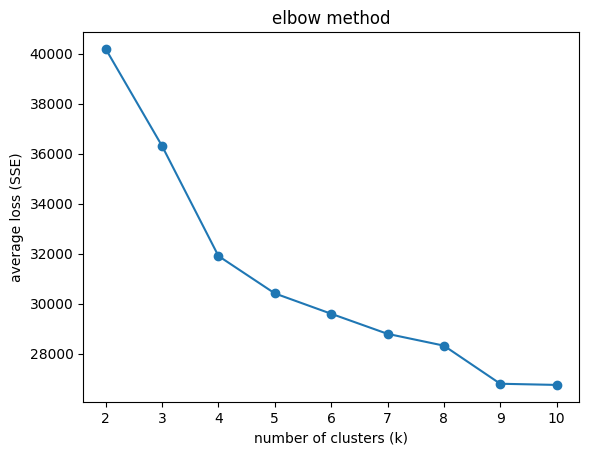

Optimal K: 6


In [12]:
losses = []
for k in range(2, 11):
   result = kmeans_with_convergence_tracking(X, k, criterion_type="max_iterations", threshold=100)
   inertia = result[2]
   final_inertia = inertia[-1] if isinstance(inertia, (list, np.ndarray)) else inertia
   losses.append(final_inertia)

plt.plot(range(2, 11), losses, marker='o')
plt.xlabel("number of clusters (k)")
plt.ylabel("average loss (SSE)")
plt.title("elbow method")
plt.show()

loss_diffs = np.diff(losses)
loss_ratios = loss_diffs[1:] / loss_diffs[:-1]
optimal_k = np.argmin(loss_ratios) 

print(f"Optimal K: {optimal_k}")

### Visualising optimal clusters found at different values of K

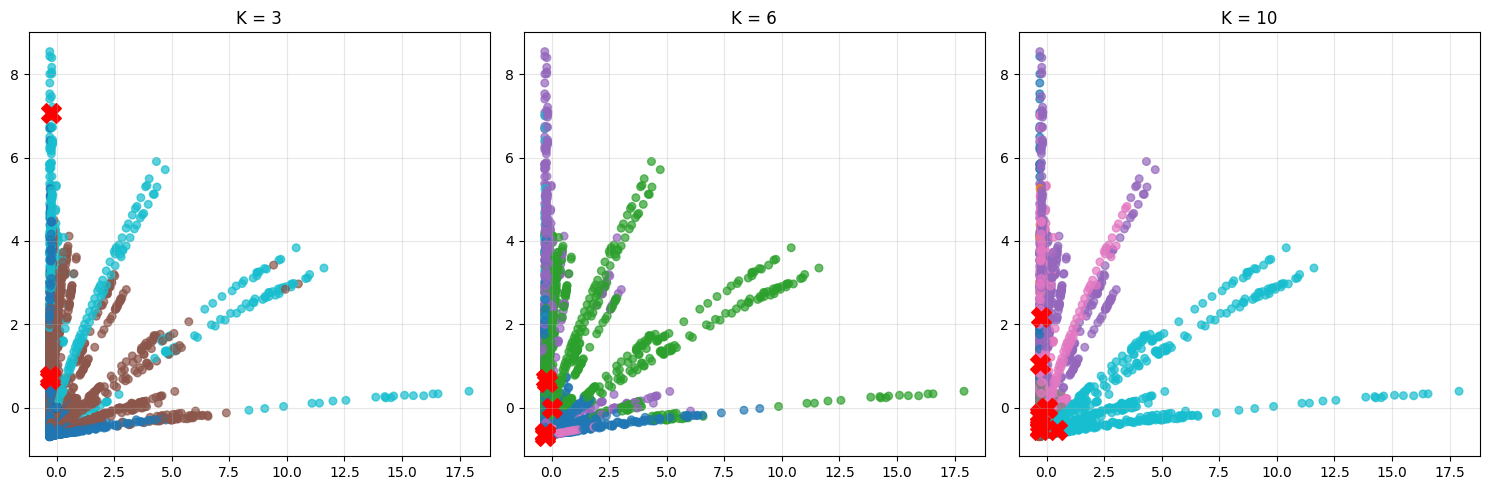

In [124]:
# Use results from your elbow analysis instead of recomputing
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
k_values = [3, 6, 10]

for i, k in enumerate(k_values):
    # Quick single run instead of full convergence tracking
    centroids = initialise_centroids_random(X, k)
    clusters = form_new_clusters(X, centroids)
    
    # Simple label assignment
    labels = []
    for point in X:
        distances = [compute_euclidean_distance(point, centroid) for centroid in centroids]
        labels.append(np.argmin(distances))
    
    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap="tab10", s=30, alpha=0.7)
    axes[i].scatter([c[0] for c in centroids], [c[1] for c in centroids], c="red", marker="X", s=200)
    axes[i].set_title(f"K = {k}")
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Dimensionality Reduction with PCA

Explained variance ratio: [0.24824712 0.15714904 0.0550635 ]
Cumulative variance: [0.24824712 0.40539616 0.46045966]

Top contributing features per component:
PC1: ['Population ages 65 and above, female', 'Methane (CH4) emissions from Power Industry (Energy) (Mt CO2e)', 'Population ages 65 and above, total', 'Population ages 65 and above, male', 'Carbon dioxide (CO2) emissions (total) excluding LULUCF (Mt CO2e)']
PC2: ['Population ages 0-14 (% of total population)', 'Population ages 0-14, male (% of male population)', 'Population ages 0-14, female (% of female population)', 'Population ages 00-04, male (% of male population)', 'Population ages 05-09, male (% of male population)']
PC3: ['Net migration', 'Primary income receipts (BoP, current US$)', 'Primary income payments (BoP, current US$)', 'Foreign direct investment, net outflows (BoP, current US$)', 'Gross value added at basic prices (GVA) (constant 2015 US$)']


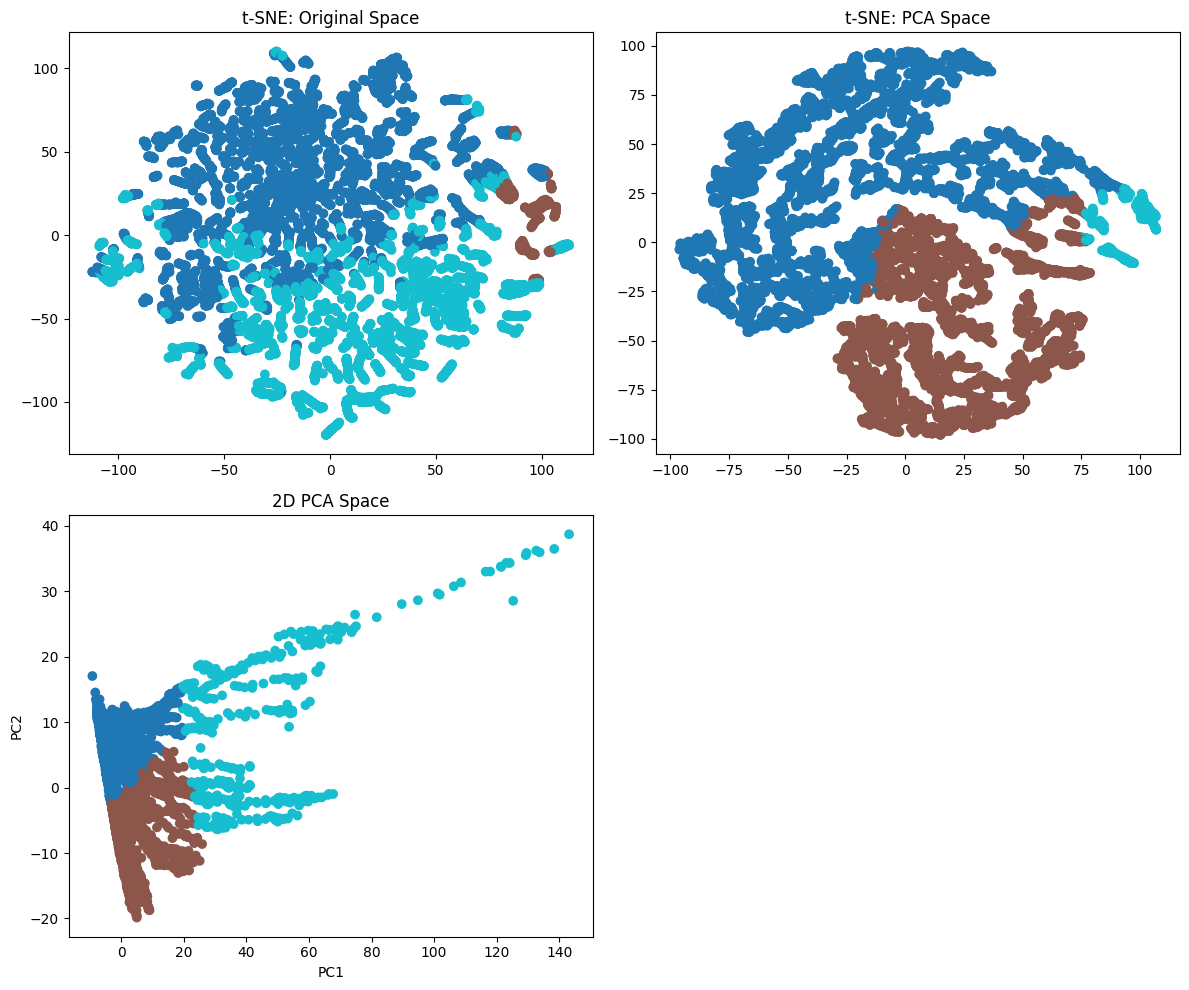

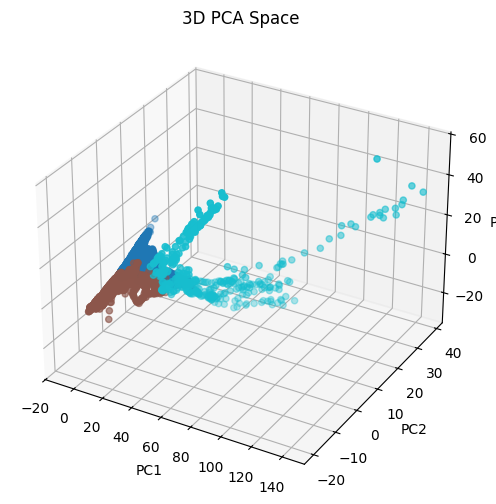

In [125]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Get feature columns (exclude ID columns)
id_cols = ['Country Name', 'Country Code', 'Year']
feature_cols = [col for col in df_normalized.columns if col not in id_cols]
X = df_normalized[feature_cols].values

# Apply PCA with different components
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)

print("Explained variance ratio:", pca.explained_variance_ratio_[:3])
print("Cumulative variance:", np.cumsum(pca.explained_variance_ratio_[:3]))

# Interpret top 3 components
print("\nTop contributing features per component:")
for i in range(3):
   top_indices = np.argsort(np.abs(pca.components_[i]))[-5:][::-1]
   print(f"PC{i+1}: {[feature_cols[idx] for idx in top_indices]}")

print(f"PC{i+1}: {[feature_cols[idx] for idx in top_indices]}")
# Cluster original vs PCA data
kmeans_orig = KMeans(n_clusters=3, random_state=42)
labels_orig = kmeans_orig.fit_predict(X)

kmeans_pca = KMeans(n_clusters=3, random_state=42)
labels_pca = kmeans_pca.fit_predict(X_pca[:, :3])

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# t-SNE comparisons
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne_orig = tsne.fit_transform(X)
X_tsne_pca = tsne.fit_transform(X_pca[:, :3])

axes[0,0].scatter(X_tsne_orig[:,0], X_tsne_orig[:,1], c=labels_orig, cmap='tab10')
axes[0,0].set_title("t-SNE: Original Space")

axes[0,1].scatter(X_tsne_pca[:,0], X_tsne_pca[:,1], c=labels_pca, cmap='tab10')
axes[0,1].set_title("t-SNE: PCA Space")

# PCA space visualizations
axes[1,0].scatter(X_pca[:,0], X_pca[:,1], c=labels_pca, cmap='tab10')
axes[1,0].set_xlabel("PC1")
axes[1,0].set_ylabel("PC2")
axes[1,0].set_title("2D PCA Space")

axes[1,1].axis('off')

plt.tight_layout()
plt.show()

# 3D PCA plot
from mpl_toolkits.mplot3d import Axes3D
fig2 = plt.figure(figsize=(8, 6))
ax = fig2.add_subplot(111, projection='3d')
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=labels_pca, cmap='tab10')
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Space")
plt.show()

## 6: Cluster Interpretation

In [16]:
def flatten_clusters(clusters, n_points):
    """Convert cluster list format to flat labels array"""
    labels = np.zeros(n_points, dtype=int)
    for cluster_id, cluster_points in enumerate(clusters):
        for point in cluster_points:
            # Find the index of this point in the original data
            idx = np.where((X == point).all(axis=1))[0]
            if len(idx) > 0:
                labels[idx[0]] = cluster_id
    return labels

def analyze_cluster_characteristics(df_data, feature_columns, clusters, centroids, k=3):
    """
    Analyze cluster characteristics using your existing variable names
    """
    # Convert clusters to flat labels
    labels = flatten_clusters(clusters, len(df_data))
   
    # Add cluster labels to the data
    analysis_data = df_data.copy()
    analysis_data['Cluster'] = labels
   
    cluster_analysis = {}
   
    for cluster_id in range(k):
        # Get data for this cluster
        cluster_data = analysis_data[analysis_data['Cluster'] == cluster_id]
        
        # Filter out regional aggregates for cleaner country analysis
        actual_countries = cluster_data[
            ~cluster_data['Country Name'].str.contains(
                'World|income|dividend|OECD|Arab|Africa|Asia|Europe|America', 
                case=False, na=False
            )
        ]
        
        if len(actual_countries) > 0:
            country_counts = actual_countries['Country Name'].value_counts()
            representative_countries = country_counts.head(5).index.tolist()
        else:
            representative_countries = cluster_data['Country Name'].value_counts().head(5).index.tolist()
       
        # Analyze features using centroids
        cluster_center = centroids[cluster_id]
        feature_analysis = []
       
        for i, feature in enumerate(feature_columns):
            feature_value = cluster_center[i]
            feature_analysis.append((feature, feature_value))
       
        # Sort by absolute value to find most distinctive features
        feature_analysis.sort(key=lambda x: abs(x[1]), reverse=True)
       
        # Create cluster persona based on countries and features
        if any(country in ['Sudan', 'Chad', 'Burkina Faso', 'Uganda', 'Kenya'] for country in representative_countries):
            persona = "Sub-Saharan Developing Nations - High youth population and rural growth"
        elif any(country in ['France', 'Sweden', 'United Kingdom', 'Germany', 'Norway'] for country in representative_countries):
            persona = "Advanced European Economies - High life expectancy and healthcare coverage"
        else:
            persona = "Mixed Development Economies - Diverse economic and social indicators"
        
        print(f"Cluster {cluster_id}: {persona}")
        print(f"Representative countries: {', '.join(representative_countries)}")

        # Store results
        cluster_analysis[cluster_id] = {
            'feature_analysis': feature_analysis,
            'representative_countries': representative_countries,
            'persona': persona,
            'size': len(cluster_data)
        }
   
    return cluster_analysis, analysis_data

# Usage with your variable names:
# Extract feature columns (exclude ID columns)
id_cols = ['Country Name', 'Country Code', 'Year']
feature_cols = [col for col in df_normalized.columns if col not in id_cols]
X = df_normalized[feature_cols].values

# Run your k-means (you'll need to implement or use your existing k-means function)
k = 3
# Assuming you have a k-means function that returns clusters and centroids
# clusters, centroids, iterations = your_kmeans_function(X, k=k)

# For now, using the PCA results from your existing code:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=k, random_state=42)
labels_flat = kmeans.fit_predict(X)

# Convert flat labels back to cluster format for your function
clusters = [[] for _ in range(k)]
for i, label in enumerate(labels_flat):
    clusters[label].append(X[i])

centroids = kmeans.cluster_centers_

# Run the analysis
cluster_analysis, analysis_data = analyze_cluster_characteristics(
    df_normalized, feature_cols, clusters, centroids, k=k
)

Cluster 0: Sub-Saharan Developing Nations - High youth population and rural growth
Representative countries: Sudan, Chad, Burkina Faso, Congo, Rep., Uganda
Cluster 1: Mixed Development Economies - Diverse economic and social indicators
Representative countries: IDA & IBRD total, IBRD only, Other small states, Qatar, Argentina
Cluster 2: Advanced European Economies - High life expectancy and healthcare coverage
Representative countries: France, Sweden, United Kingdom, Denmark, Switzerland


In [127]:
# Cluster Interpretation based on PCA results
df_clustered = df_normalized.copy()
df_clustered['Cluster'] = labels_pca

# Clean country names (remove regional aggregates)
actual_countries = df_clustered[~df_clustered['Country Name'].str.contains('dividend|income|Africa|Asia|World|OECD', case=False, na=False)]

print("Representative Countries by Cluster:")
for cluster in [0, 1, 2]:
    cluster_countries = actual_countries[actual_countries['Cluster'] == cluster]['Country Name'].unique()[:4]
    print(f"Cluster {cluster}: {', '.join(cluster_countries)}")

# Interpret clusters based on PCA component meanings
cluster_interpretations = {
    0: "Aging Industrial Nations - High elderly population (65+) with established industrial emissions infrastructure",
    1: "Youth-Dominant Countries - High proportion of young population (0-14 years), typical of developing nations",
    2: "Economically Integrated States - High international capital flows, migration, and global economic connectivity"
}

print("\nDevelopment Cluster Personas:")
for cluster in [0, 1, 2]:
    count = sum(labels_pca == cluster)
    print(f"Cluster {cluster} ({count} observations): {cluster_interpretations[cluster]}")

# Development level analysis
print(f"\nDevelopment Interpretation:")
print(f"PC1 captures demographic transition + industrialization (24.8% variance)")
print(f"PC2 captures youth demographics of developing countries (15.7% variance)")  
print(f"PC3 captures global economic integration (5.5% variance)")
print(f"Total variance captured: 46.0% - indicates significant information loss in PCA")

Representative Countries by Cluster:
Cluster 0: Afghanistan, Albania, Algeria, Angola
Cluster 1: Albania, Algeria, Andorra, Antigua and Barbuda
Cluster 2: IBRD only, IDA & IBRD total

Development Cluster Personas:
Cluster 0 (7502 observations): Aging Industrial Nations - High elderly population (65+) with established industrial emissions infrastructure
Cluster 1 (5266 observations): Youth-Dominant Countries - High proportion of young population (0-14 years), typical of developing nations
Cluster 2 (408 observations): Economically Integrated States - High international capital flows, migration, and global economic connectivity

Development Interpretation:
PC1 captures demographic transition + industrialization (24.8% variance)
PC2 captures youth demographics of developing countries (15.7% variance)
PC3 captures global economic integration (5.5% variance)
Total variance captured: 46.0% - indicates significant information loss in PCA


## 7. Creative Extensions

### Outlier Analysis

In [134]:
feature_cols = [col for col in df_normalized.columns if col not in ['Country Name', 'Country Code', 'Year']]
X = df_normalized[feature_cols].dropna().values

# Identify outliers
z_scores = np.abs(stats.zscore(X))
outliers = (z_scores > 3).any(axis=1)
X_clean = X[~outliers]

print(f"Outliers removed: {outliers.sum()}")
print(f"Data remaining: {len(X_clean)}")

# Cluster with and without outliers
kmeans_with = KMeans(n_clusters=3, random_state=42)
kmeans_without = KMeans(n_clusters=3, random_state=42)

labels_with = kmeans_with.fit_predict(X)
labels_without = kmeans_without.fit_predict(X_clean)

print(f"With outliers: {np.bincount(labels_with)}")
print(f"Without outliers: {np.bincount(labels_without)}")
print(f"Quality improvement: {((kmeans_with.inertia_ - kmeans_without.inertia_)/kmeans_with.inertia_*100):.1f}%")

Outliers removed: 10410
Data remaining: 2766
With outliers: [7590  412 5174]
Without outliers: [ 881 1113  772]
Quality improvement: 93.7%


### Alternative Clustering (DBSCAN)

DBSCAN: 43 clusters, 210 noise points


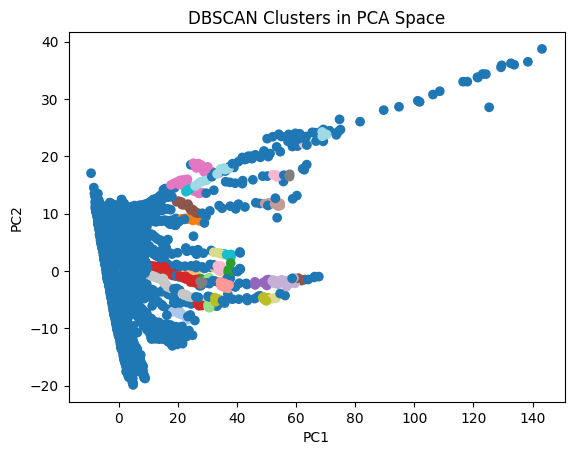

In [144]:
# USED GEEKSFORGEEKS FOR LOTS OF HELP - SOURCE -
Use PCA-reduced data (you can use all 10 components or just the top few)
dbscan = DBSCAN(eps=1.5, min_samples=3)
labels_dbscan = dbscan.fit_predict(X_pca[:, :3])  # or use X_pca if you want all components

# Analyze results
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)

print(f"DBSCAN: {n_clusters_dbscan} clusters, {n_noise} noise points")

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_dbscan, cmap='tab20')
plt.title("DBSCAN Clusters in PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()